In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [13]:
np.random.seed(101)

orders = 1000

df = pd.DataFrame({
    "Order_ID": range(1, orders + 1),
    "Order_Date": pd.date_range(start="2025-01-01", periods=orders, freq="h"),
    "Category": np.random.choice(
        ["Fruits & Vegetables", "Dairy", "Snacks", "Beverages", "Household"],
        orders
    ),
    "Order_Value": np.random.randint(100, 2000, orders),
    "Delivery_Time_Min": np.random.randint(5, 40, orders),
    "Customer_Rating": np.round(np.random.uniform(2.5, 5.0, orders), 1)
})


In [14]:
print(df.head())
print(df.info())
print(df.describe())



   Order_ID          Order_Date             Category  Order_Value  \
0         1 2025-01-01 00:00:00            Beverages          562   
1         2 2025-01-01 01:00:00                Dairy         1532   
2         3 2025-01-01 02:00:00            Beverages         1760   
3         4 2025-01-01 03:00:00                Dairy         1829   
4         5 2025-01-01 04:00:00  Fruits & Vegetables         1287   

   Delivery_Time_Min  Customer_Rating  
0                 39              4.7  
1                 39              3.3  
2                 22              3.7  
3                 13              4.8  
4                 36              3.7  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Order_ID           1000 non-null   int64         
 1   Order_Date         1000 non-null   datetime64[ns]
 2   Category       

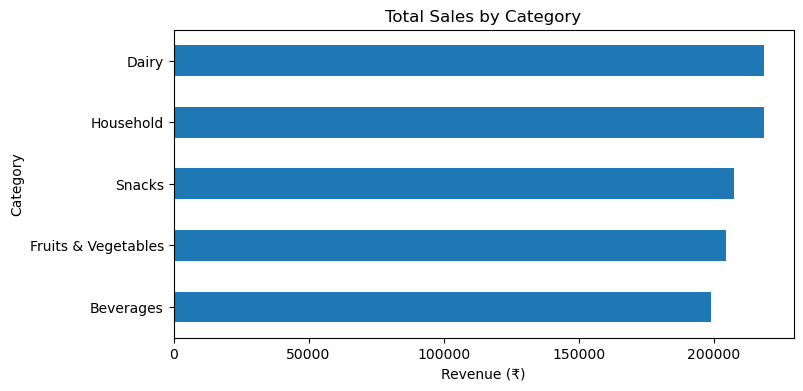

In [15]:
category_sales = df.groupby("Category")["Order_Value"].sum().sort_values()

category_sales.plot(kind="barh", figsize=(8,4))
plt.title("Total Sales by Category")
plt.xlabel("Revenue (₹)")
plt.show()


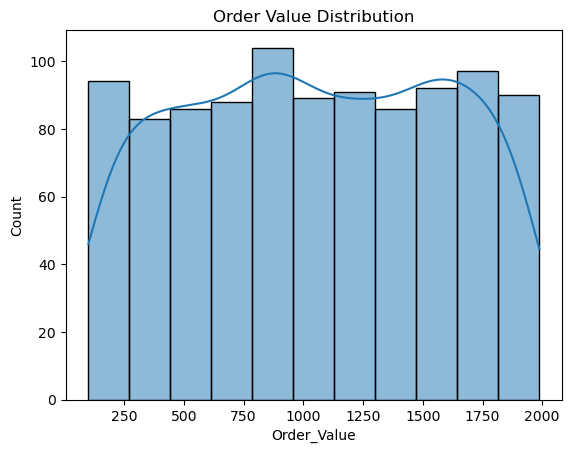

In [16]:
sns.histplot(df["Order_Value"], kde=True)
plt.title("Order Value Distribution")
plt.show()


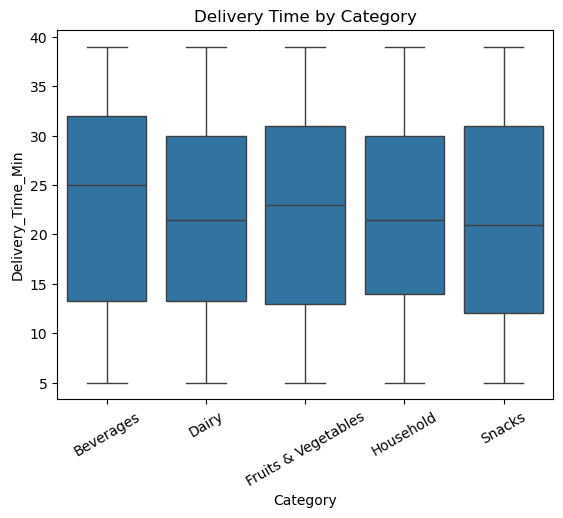

In [17]:
sns.boxplot(x="Category", y="Delivery_Time_Min", data=df)
plt.xticks(rotation=30)
plt.title("Delivery Time by Category")
plt.show()


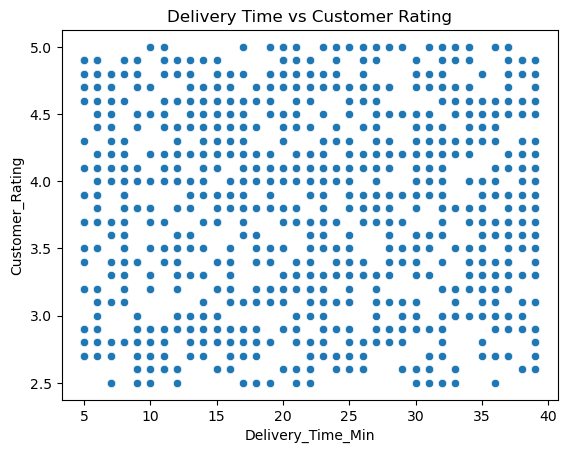

In [18]:
sns.scatterplot(
    x="Delivery_Time_Min",
    y="Customer_Rating",
    data=df
)
plt.title("Delivery Time vs Customer Rating")
plt.show()


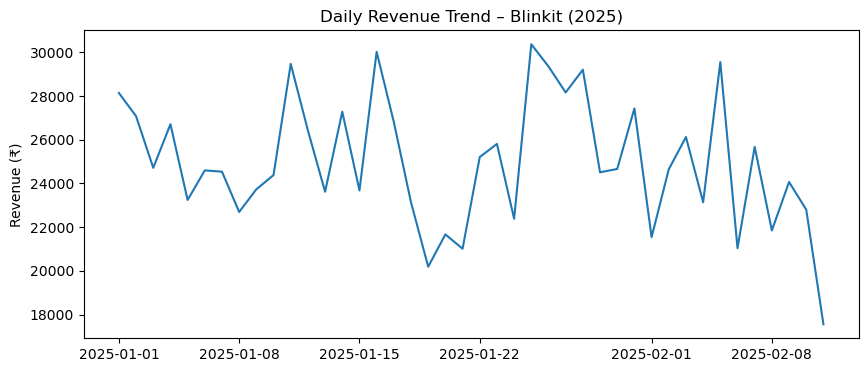

In [19]:
df["Date"] = df["Order_Date"].dt.date
daily_sales = df.groupby("Date")["Order_Value"].sum()

plt.figure(figsize=(10,4))
plt.plot(daily_sales)
plt.title("Daily Revenue Trend – Blinkit (2025)")
plt.ylabel("Revenue (₹)")
plt.show()


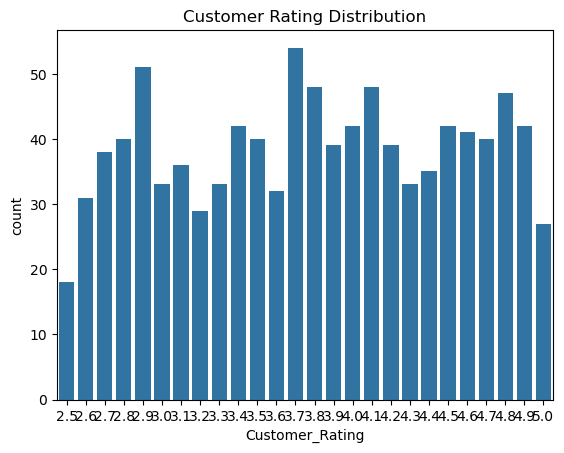

In [20]:
sns.countplot(x=df["Customer_Rating"])
plt.title("Customer Rating Distribution")
plt.show()
